In [28]:
import geopandas as gpd
import pandas as pd
import h3pandas
import numpy as np
from matplotlib import pyplot as plt

from libpysal.weights import higher_order, Queen
from splot.esda import plot_local_autocorrelation, lisa_cluster
from esda.moran import Moran_Local_BV, Moran_Local

sp = gpd.read_file("../../data/sp.geojson")

In [11]:
effects = pd.read_csv(
    "/Users/camillaperotto/Documents/pde-sp/01_AccessPipeline/data/effects/pond_T001_effects.csv",
    sep=';', decimal=',', usecols=['h3_09', 'AAreal___delta', 'AAreal___deltaPerc'])
effects.head(3)

,h3_09,AAreal___delta,AAreal___deltaPerc
0,89a81000003ffff,-10381146.0,-16.795761
1,89a81000007ffff,867678.0,21.197197
2,89a8100000bffff,27870759.0,9.053906


In [29]:
real__2013 = pd.read_csv(f"../../data/access/real___2013/active.csv", sep=';') #.drop(columns=['pond_T001', 'N_HOUSING'])
real__2022 = pd.read_csv(f"../../data/access/real___2022/active.csv", sep=';') #.drop(columns=['pond_T001', 'N_HOUSING'])
real = real__2013.merge(real__2022, on="h3_09", suffixes=["___2013", "___2022"])
real["DELTA_T001"] = real.T001___2022-real.T001___2013
real["DELTA_T001_PERC"] = 100*real["DELTA_T001"]/real.T001___2013
real["DELTA_HEXS"] = real.N_HEXS___2022-real.N_HEXS___2013
real["DELTA_HEXS_PERC"] = 100*real["DELTA_HEXS"]/real.N_HEXS___2013
real["DELTA_N_HOUSING"] = real.N_HOUSING___2022-real.N_HOUSING___2013
real["DELTA_N_HOUSING_PERC"] = 100*real["DELTA_N_HOUSING"]/real.N_HOUSING___2013
real["DELTA_ACCESS_POND"] = real.pond_T001___2022 - real.pond_T001___2013
real["DELTA_ACCESS_POND_PERC"] = 100*real["DELTA_ACCESS_POND"]/real.pond_T001___2013
del real__2013
del real__2022
real = real.set_index("h3_09")
real = real.h3.h3_to_geo_boundary()
real.head(3)

,T001___2013,N_HEXS___2013,N_HOUSING___2013,pond_T001___2013,T001___2022,N_HEXS___2022,N_HOUSING___2022,pond_T001___2022,DELTA_T001,DELTA_T001_PERC,DELTA_HEXS,DELTA_HEXS_PERC,DELTA_N_HOUSING,DELTA_N_HOUSING_PERC,DELTA_ACCESS_POND,DELTA_ACCESS_POND_PERC,geometry
h3_09,,,,,,,,,,,,,,,,,
89a81000003ffff,116088,573,443.0,51426984.0,89577,518,690.0,61808130.0,-26511,-22.836986,-55,-9.598604,247.0,55.756208,10381146.0,20.186185,"POLYGON ((-46.63251 -23.71107, -46.63145 -23.7..."
89a81000007ffff,103355,533,48.0,4961040.0,75803,476,54.0,4093362.0,-27552,-26.657636,-57,-10.694184,6.0,12.500000,-867678.0,-17.489841,"POLYGON ((-46.63552 -23.7094, -46.63446 -23.70..."
89a8100000bffff,146403,622,2293.0,335702079.0,96620,548,3186.0,307831320.0,-49783,-34.004085,-74,-11.897106,893.0,38.944614,-27870759.0,-8.302230,"POLYGON ((-46.62941 -23.70968, -46.62834 -23.7..."


In [18]:
real.DELTA_ACCESS_POND.mean() < 583510765.0

True

In [19]:
real.columns

Index(['T001___2013', 'N_HEXS___2013', 'N_HOUSING___2013', 'pond_T001___2013',
       'T001___2022', 'N_HEXS___2022', 'N_HOUSING___2022', 'pond_T001___2022',
       'DELTA_T001', 'DELTA_T001_PERC', 'DELTA_HEXS', 'DELTA_HEXS_PERC',
       'DELTA_N_HOUSING', 'DELTA_N_HOUSING_PERC', 'DELTA_ACCESS_POND',
       'DELTA_ACCESS_POND_PERC', 'geometry'],
      dtype='object')

In [ ]:
real[""]

In [16]:
_r = real.reset_index()
_r[_r.h3_09=="89a810760abffff"]

,h3_09,T001___2013,N_HEXS___2013,N_HOUSING___2013,pond_T001___2013,T001___2022,N_HEXS___2022,N_HOUSING___2022,pond_T001___2022,DELTA_T001,DELTA_T001_PERC,DELTA_HEXS,DELTA_HEXS_PERC,DELTA_N_HOUSING,DELTA_N_HOUSING_PERC,DELTA_ACCESS_POND,DELTA_ACCESS_POND_PERC,geometry
12465,89a810760abffff,458683,1465,2481.0,1.137993e+09,273683,1187,2026.0,554481758.0,-185000,-40.332866,-278,-18.976109,-455.0,-18.339379,-583510765.0,-51.275448,"POLYGON ((-46.65274 -23.46304, -46.65168 -23.4..."


In [13]:
x = real.DELTA_ACCESS_POND_PERC / real.DELTA_N_HOUSING_PERC
x.describe()

/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/numpy/core/_methods.py:49: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


count    1.183200e+04
mean              NaN
std               NaN
min              -inf
25%      5.760689e-02
50%      1.011426e+00
75%      2.243647e+00
max               inf
dtype: float64

In [34]:
real.columns

Index(['T001___2013', 'N_HEXS___2013', 'N_HOUSING___2013', 'pond_T001___2013',
       'T001___2022', 'N_HEXS___2022', 'N_HOUSING___2022', 'pond_T001___2022',
       'DELTA_T001', 'DELTA_T001_PERC', 'DELTA_HEXS', 'DELTA_HEXS_PERC',
       'DELTA_N_HOUSING', 'DELTA_N_HOUSING_PERC', 'DELTA_ACCESS_POND',
       'DELTA_ACCESS_POND_PERC', 'geometry'],
      dtype='object')

In [35]:
real["elast_housing"] = real.DELTA_ACCESS_POND_PERC/real.DELTA_N_HOUSING_PERC

In [38]:
type(real)

geopandas.geodataframe.GeoDataFrame

In [46]:
real.replace([np.inf, -np.inf], np.nan).elast_housing.max()

6866.645161290324

<Axes: >

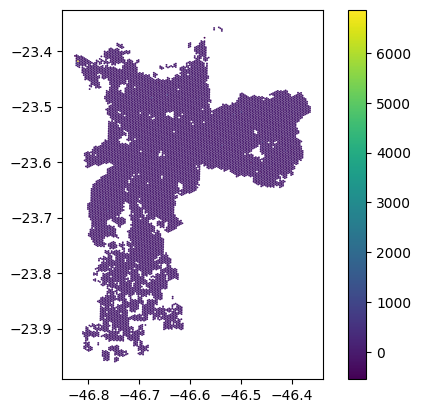

In [ ]:
real.replace([np.inf, -np.inf], np.nan).plot("elast_housing", cmap='viridis', legend=True)

In [30]:
w = Queen.from_dataframe(real)
w2 = higher_order(w, k=2, lower_order=True)

w.transform = 'r'
w2.transform = 'r'

ws = [w, w2]
#ws = [w]

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_14941/2537910187.py:1: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(real)


In [56]:
real.columns

Index(['T001___2013', 'N_HEXS___2013', 'N_HOUSING___2013', 'pond_T001___2013',
       'T001___2022', 'N_HEXS___2022', 'N_HOUSING___2022', 'pond_T001___2022',
       'DELTA_T001', 'DELTA_T001_PERC', 'DELTA_HEXS', 'DELTA_HEXS_PERC',
       'DELTA_N_HOUSING', 'DELTA_N_HOUSING_PERC', 'DELTA_ACCESS_POND',
       'DELTA_ACCESS_POND_PERC', 'geometry'],
      dtype='object')

In [31]:
bivariates = []

"""
for c in ['DELTA_T001_PERC', 'DELTA_HEXS_PERC', 'DELTA_N_HOUSING_PERC']:
    bivariates.append([c, 'DELTA_ACCESS_POND_PERC'])
"""

for c in ['DELTA_T001', 'DELTA_HEXS', 'DELTA_N_HOUSING']:
    bivariates.append([c, 'pond_T001___2022'])


In [26]:
bivariates

[['DELTA_T001', 'pond_T001___2022'],
 ['DELTA_HEXS', 'pond_T001___2022'],
 ['DELTA_N_HOUSING', 'pond_T001___2022']]

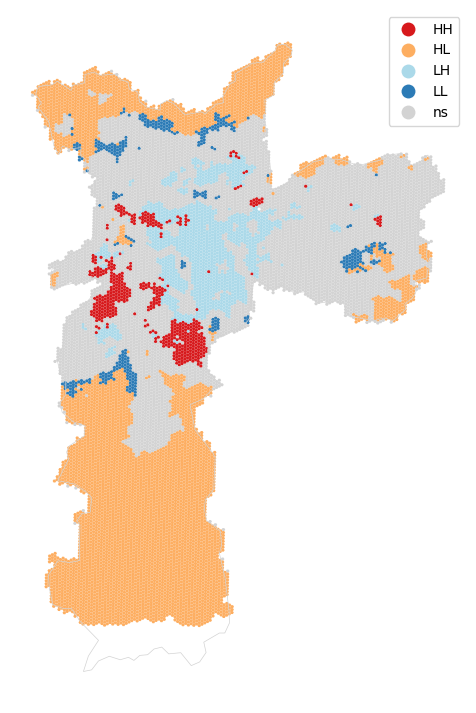

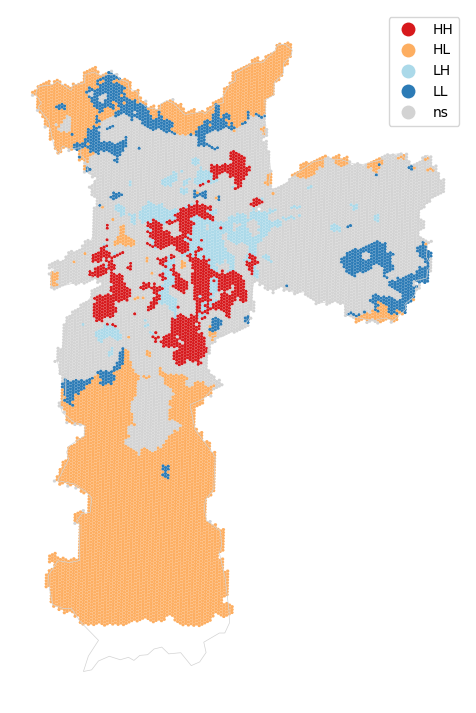

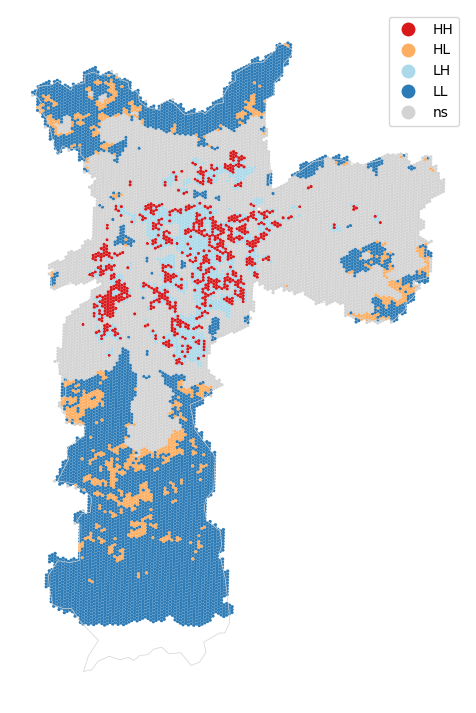

In [32]:
translate = {
    "DELTA_T001": "(A)   Cenário I (Δ Empregos)", 
    "DELTA_HEXS": "(C)   Cenário III (Δ Transporte)", 
    "DELTA_N_HOUSING": "(B)   Cenário II (Δ População)"
}

for biv in bivariates:
    k = 1

    for _w in ws:
        x = real[biv[0]].values
        y = real[biv[1]].values
        moran_loc_bv = Moran_Local_BV(x, y, _w)

        coisa, ax = lisa_cluster(moran_loc_bv, real, p=0.05, figsize=(12, 9))
        sp.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5, zorder=1)
        #ax.set_title(translate[biv[0]], fontfamily="Times New Roman", fontsize=15)
        figname = f'LOCALMORAN___{biv[0]}__{biv[1]}__w{k}.png'
        if 'PERC' in biv[0]: figname = 'PERC_'+figname
        plt.savefig('./'+figname, dpi=900)
        k += 1
        break

In [ ]:
"""
y = housing.delta_housing.values
moranLoc = Moran_Local(y, wHousing2)
coisa, ax = lisa_cluster(moranLoc, housing, p=0.05, figsize=(12, 9))
sp.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5, zorder=1)
ax.set_title("(D)   Clusters LISA (p < 0,05)", fontfamily="Times New Roman", fontsize=15)
plt.savefig(f'./localMoran_deltaHousing2.png', dpi=900)
"""

In [38]:
real[["pond_T001___2013", "pond_T001___2022"]].max()

pond_T001___2013    1.410437e+10
pond_T001___2022    1.086351e+10
dtype: float64

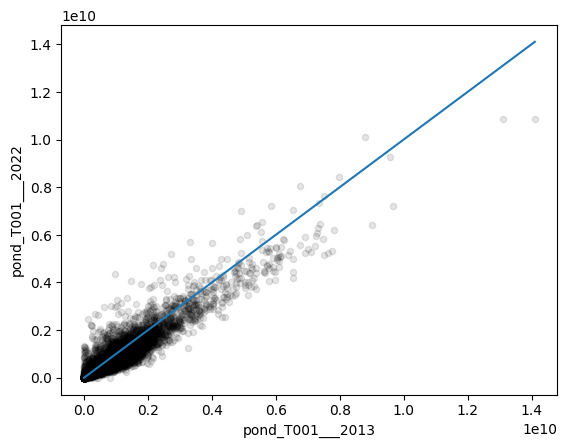

In [41]:
ax = real.plot(kind='scatter', x="pond_T001___2013", y="pond_T001___2022", c='black', alpha=0.1)
ax.plot([1, real[["pond_T001___2013", "pond_T001___2022"]].max().max()], [1, real[["pond_T001___2013", "pond_T001___2022"]].max().max()])

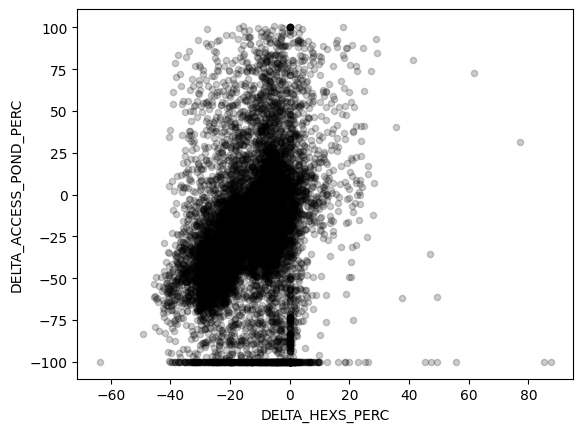

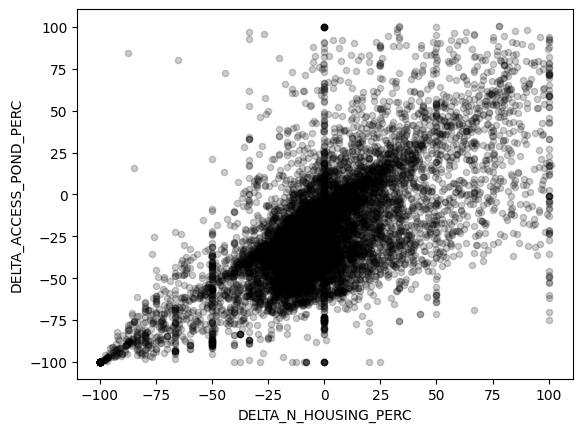

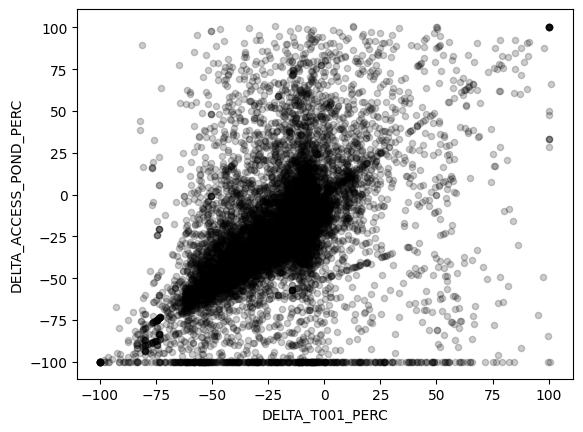

In [29]:
#fig, ax = #plt.scatter(real.DELTA_N_HOUSING_PERC, real.DELTA_ACCESS_POND_PERC, c="black", alpha=0.2)
col = "DELTA_HEXS_PERC"
for col in ["DELTA_HEXS_PERC", "DELTA_N_HOUSING_PERC", "DELTA_T001_PERC"]:

    df = real.loc[(abs(real[col])<101) & (abs(real.DELTA_ACCESS_POND_PERC)<101)]
    ax = df.plot(kind="scatter", x=col, y="DELTA_ACCESS_POND_PERC", c="black", alpha=0.2)
    plt.savefig(f"./{col}.png", dpi=900)


In [32]:
import statsmodels.api as sm

/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


                            OLS Regression Results                            
Dep. Variable:            T001___2013   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 4.752e+33
Date:                Sun, 22 Jun 2025   Prob (F-statistic):               0.00
Time:                        19:54:01   Log-Likelihood:             2.8872e+05
No. Observations:               14457   AIC:                        -5.774e+05
Df Residuals:                   14453   BIC:                        -5.774e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -4.425e-11   8.48e-12  

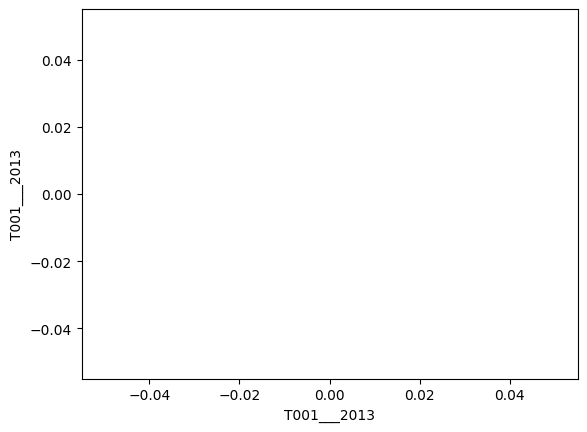

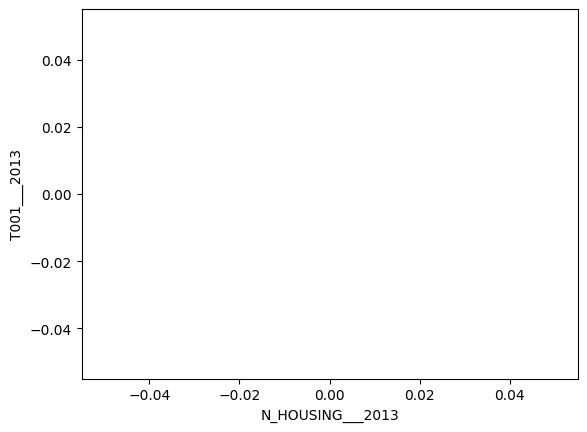

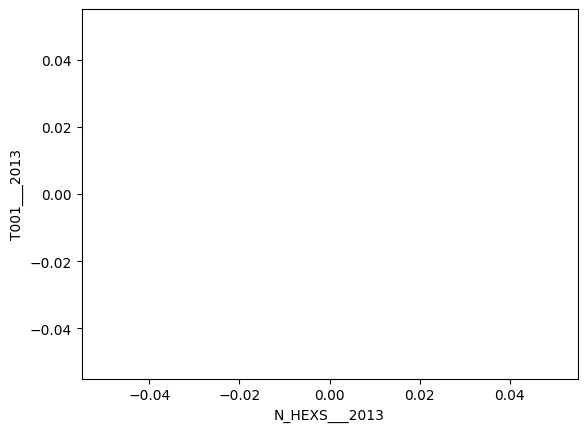

In [63]:


cols = ["T001___2013", "N_HOUSING___2013", "N_HEXS___2013"]
for col in cols:

    df = df.copy() #real.loc[(abs(real[col])<101) & (abs(real.pond_T001___2013)<101)]
    df = df.replace(0, 1)
    df[col] = np.log(df[col])
    
    df['T001___2013'] = np.log(df['T001___2013'])
    ax = df.plot(kind="scatter", x=col, y="T001___2013", c="black", alpha=0.2)
    plt.savefig(f"./{col}_ELAST.png", dpi=900)

real = real.replace(0,1)
X = sm.add_constant(real[cols])
model = sm.OLS(real['T001___2013'], X).fit()

# Ver resumo
print(model.summary())


In [33]:
real

,h3_09,T001___2013,N_HEXS___2013,N_HOUSING___2013,pond_T001___2013,T001___2022,N_HEXS___2022,N_HOUSING___2022,pond_T001___2022,DELTA_T001,DELTA_T001_PERC,DELTA_HEXS,DELTA_HEXS_PERC,DELTA_N_HOUSING,DELTA_N_HOUSING_PERC,DELTA_ACCESS_POND,DELTA_ACCESS_POND_PERC
0,89a81000003ffff,116088,573,443.0,51426984.0,89577,518,690.0,61808130.0,-26511,-22.836986,-55,-9.598604,247.0,55.756208,10381146.0,20.186185
1,89a81000007ffff,103355,533,48.0,4961040.0,75803,476,54.0,4093362.0,-27552,-26.657636,-57,-10.694184,6.0,12.500000,-867678.0,-17.489841
2,89a8100000bffff,146403,622,2293.0,335702079.0,96620,548,3186.0,307831320.0,-49783,-34.004085,-74,-11.897106,893.0,38.944614,-27870759.0,-8.302230
3,89a8100000fffff,169598,682,841.0,142631918.0,120196,606,918.0,110339928.0,-49402,-29.128881,-76,-11.143695,77.0,9.155767,-32291990.0,-22.640087
4,89a81000013ffff,116951,560,507.0,59294157.0,84327,506,1063.0,89639601.0,-32624,-27.895443,-54,-9.642857,556.0,109.664694,30345444.0,51.177798
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14452,89a8108f3c7ffff,30,104,2.0,60.0,6,104,1.0,6.0,-24,-80.000000,0,0.000000,-1.0,-50.000000,-54.0,-90.000000
14453,89a8108f3cbffff,26,143,4.0,104.0,7,143,4.0,28.0,-19,-73.076923,0,0.000000,0.0,0.000000,-76.0,-73.076923
14454,89a8108f3cfffff,26,145,2.0,52.0,7,145,1.0,7.0,-19,-73.076923,0,0.000000,-1.0,-50.000000,-45.0,-86.538462
14455,89a8108f3d7ffff,26,83,2.0,52.0,6,83,1.0,6.0,-20,-76.923077,0,0.000000,-1.0,-50.000000,-46.0,-88.461538
